# TP 1 — Exploration d'un jeu de données : `clients.csv` — **CORRIGÉ ENSEIGNANT**
**Analyse de données — Master IA / Master RSD** · Chapitre 1 : Introduction à l'analyse de données

Ce notebook contient :
- **Partie 0 (enseignant)** : la génération du fichier fictif `clients.csv` (reproductible, graine fixe) ;
- la **solution complète** de chaque partie du notebook étudiant, avec les sorties ;
- des **notes pédagogiques** (💡) : erreurs fréquentes, questions à poser en séance.

> Le notebook étudiant a exactement la même structure : vous pouvez projeter celui-ci partie par partie.

## Partie 0 — Génération du jeu de données (enseignant)
Jeu **entièrement fictif** : 1 000 clients, 8 variables (6 numériques, 2 catégorielles), avec des défauts volontaires :
- **37 revenus manquants** ;
- **1 revenu aberrant** (999 999 DA) ;
- segments A / B / C avec effectifs **412 / 321 / 267**.

Exécutez cette cellule une fois, puis distribuez `clients.csv` avec le notebook étudiant.

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)          # graine fixe -> fichier identique à chaque exécution
n = 1000

# Segment : effectifs exacts attendus par l'énoncé (A 412, B 321, C 267)
segment = np.array(["A"] * 412 + ["B"] * 321 + ["C"] * 267)
rng.shuffle(segment)

age = rng.normal(42.3, 12.1, n).round().clip(18, 87).astype(int)
age[:2] = [18, 87]                          # bornes min / max de l'énoncé

mediane = pd.Series(segment).map({"A": 52000, "B": 37000, "C": 31000}).to_numpy()
revenu = (mediane * rng.lognormal(0, 0.45, n)).clip(9500).round(-2)

nb_enfants = rng.poisson(1.4, n).clip(0, 6)
anciennete = rng.integers(0, 21, n)                         # années comme client
nb_achats = rng.poisson(pd.Series(segment).map({"A": 12, "B": 8, "C": 5}).to_numpy())

df_gen = pd.DataFrame({
    "id": np.arange(1, n + 1),
    "age": age,
    "revenu": revenu,
    "nb_enfants": nb_enfants,
    "anciennete": anciennete,
    "nb_achats": nb_achats,
    "email": [f"client{i:04d}@exemple.dz" for i in range(1, n + 1)],
    "segment": segment,
})

# Défauts volontaires à faire découvrir aux étudiants
idx = rng.choice(np.arange(2, n), size=38, replace=False)
df_gen.loc[idx[0], "revenu"] = 999999                       # 1 valeur aberrante (erreur de saisie)
df_gen.loc[idx[1:], "revenu"] = np.nan                      # 37 valeurs manquantes

df_gen["revenu"] = df_gen["revenu"].astype("Int64")         # entiers dans le CSV, case vide pour NaN
df_gen.to_csv("clients.csv", sep=";", index=False, encoding="utf-8")
print("clients.csv écrit :", df_gen.shape)

clients.csv écrit : (1000, 8)


---
## Partie 1 — Vérifier l'installation
Si une bibliothèque manque, dans le terminal (Anaconda Prompt) :
```
conda activate data
pip install pandas numpy matplotlib seaborn scikit-learn jupyter
```

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Python  :", sys.version.split()[0])
print("pandas  :", pd.__version__)
print("numpy   :", np.__version__)
print("seaborn :", sns.__version__)

Python  : 3.13.8
pandas  : 2.3.3
numpy   : 2.3.4
seaborn : 0.13.2


---
## Partie 2 — Échauffement : des données brutes à la décision
Reprenons l'exemple du cours : les ventes d'un café sur une semaine ($n = 7$ individus, $p = 2$ variables).

**Données brutes → Analyse → Décision**

In [3]:
cafe = pd.DataFrame({
    "jour":     ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"],
    "boissons": [45, 52, 38, 60, 55, 70, 40],
    "recette":  [180, 208, 152, 240, 220, 280, 160],   # en DA
})
cafe

,jour,boissons,recette
0,Lundi,45,180
1,Mardi,52,208
2,Mercredi,38,152
3,Jeudi,60,240
4,Vendredi,55,220
5,Samedi,70,280
6,Dimanche,40,160


**Questions**
1. Total des boissons vendues et total des recettes.
2. Moyenne quotidienne des boissons vendues (arrondie à 0,1).
3. Le jour le plus rentable.
4. Quelle **décision** proposeriez-vous au gérant ?

In [4]:
total_boissons = cafe["boissons"].sum()
total_recette  = cafe["recette"].sum()
moyenne_jour   = round(cafe["boissons"].mean(), 1)
meilleur_jour  = cafe.loc[cafe["recette"].idxmax(), "jour"]

print(total_boissons, total_recette, moyenne_jour, meilleur_jour)

360 1440 51.4 Samedi


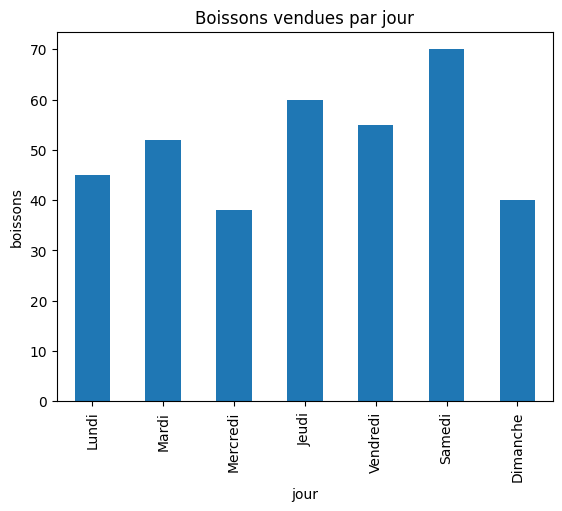

In [5]:
# Visualiser pour convaincre : le week-end se détache-t-il ?
cafe.plot.bar(x="jour", y="boissons", legend=False, title="Boissons vendues par jour")
plt.ylabel("boissons")
plt.show()

**Décision attendue :** le samedi (70 boissons, 280 DA) est nettement au-dessus de la moyenne (51,4). On peut **renforcer le stock et le personnel le samedi** pour répondre à la demande et maximiser la recette.

💡 *À souligner* : le dimanche (40) est sous la moyenne — « le week-end » n'est pas homogène. Une bonne décision s'appuie sur les chiffres, pas sur l'intuition.

---
## Partie 3 — Exercice guidé : explorer `clients.csv`
Jeu de données **fictif** : 1 000 clients, 8 variables. Cinq étapes, dans l'ordre.

### Étape 1 — Importer le fichier
Le fichier utilise le séparateur **`;`** (convention des CSV français) et l'encodage **utf-8**.

💡 **Piège à montrer en séance** : sans `sep=";"`, Pandas lit tout dans **une seule colonne**.

In [6]:
pd.read_csv("clients.csv").shape      # (1000, 1) -> mauvais séparateur !

(1000, 1)

In [7]:
df = pd.read_csv("clients.csv", sep=";", encoding="utf-8")
df.head()

,id,age,revenu,nb_enfants,anciennete,nb_achats,email,segment
0,1,18,49200.0,2,3,7,client0001@exemple.dz,C
1,2,87,54900.0,3,10,12,client0002@exemple.dz,A
2,3,55,40200.0,1,13,17,client0003@exemple.dz,A
3,4,67,31600.0,1,11,3,client0004@exemple.dz,C
4,5,40,60300.0,0,13,17,client0005@exemple.dz,A


### Étape 2 — Dimensions et types
Utilisez `shape` et `dtypes`. Combien de colonnes numériques ? Combien de catégorielles ?

In [8]:
print(df.shape)
df.dtypes

(1000, 8)


id              int64
age             int64
revenu        float64
nb_enfants      int64
anciennete      int64
nb_achats       int64
email          object
segment        object
dtype: object

In [9]:
nb_numeriques    = df.select_dtypes(include="number").shape[1]
nb_categorielles = df.select_dtypes(include="object").shape[1]
print(nb_numeriques, nb_categorielles)

6 2


💡 *Question à poser* : pourquoi `revenu` est-il en `float64` alors que les autres entiers sont en `int64` ? → Pandas représente une valeur manquante par `NaN`, qui est un **float** : une seule case vide suffit à convertir toute la colonne.

### Étape 3 — Valeurs manquantes
Utilisez `info()` puis `isna().sum()`.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          1000 non-null   int64  
 1   age         1000 non-null   int64  
 2   revenu      963 non-null    float64
 3   nb_enfants  1000 non-null   int64  
 4   anciennete  1000 non-null   int64  
 5   nb_achats   1000 non-null   int64  
 6   email       1000 non-null   object 
 7   segment     1000 non-null   object 
dtypes: float64(1), int64(5), object(2)
memory usage: 62.6+ KB


In [11]:
manquants = df.isna().sum().sort_values(ascending=False)
manquants

revenu        37
id             0
age            0
nb_enfants     0
anciennete     0
nb_achats      0
email          0
segment        0
dtype: int64

### Étape 4 — Statistiques descriptives et effectifs par segment

In [12]:
df.describe(include="all")

,id,age,revenu,nb_enfants,anciennete,nb_achats,email,segment
count,1000.000000,1000.000000,963.000000,1000.000000,1000.000000,1000.000000,1000,1000
unique,NaN,NaN,NaN,NaN,NaN,NaN,1000,3
top,NaN,NaN,NaN,NaN,NaN,NaN,client0001@exemple.dz,A
freq,NaN,NaN,NaN,NaN,NaN,NaN,1,412
mean,500.500000,41.868000,45706.956386,1.440000,10.463000,8.813000,NaN,NaN
std,288.819436,11.738158,38330.349749,1.189881,6.087832,4.223016,NaN,NaN
min,1.000000,18.000000,9600.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,250.750000,33.000000,28650.000000,1.000000,5.000000,6.000000,NaN,NaN
50%,500.500000,42.000000,39900.000000,1.000000,11.000000,8.000000,NaN,NaN
75%,750.250000,50.000000,56250.000000,2.000000,16.000000,12.000000,NaN,NaN


In [13]:
effectifs = df["segment"].value_counts(dropna=False)
effectifs

segment
A    412
B    321
C    267
Name: count, dtype: int64

💡 *À faire lire dans `describe()`* : `count` du revenu = **963** (≠ 1000 → les 37 NaN) ; `max` du revenu = **999 999** alors que le 75ᵉ centile est vers 55 000 ; l'écart-type est gonflé par cette seule valeur.

### Étape 5 — Une anomalie et une question métier
Comparez le **maximum** du revenu avec son **99ᵉ centile**. Que constatez-vous ?

In [14]:
revenu_max = df["revenu"].max()
revenu_p99 = df["revenu"].quantile(0.99)
print(revenu_max, revenu_p99)

999999.0 117590.0


In [15]:
# Qui est ce client ?
df[df["revenu"] > 200000]

,id,age,revenu,nb_enfants,anciennete,nb_achats,email,segment
797,798,46,999999.0,1,9,6,client0798@exemple.dz,C


**Réponse attendue**
- **Anomalie :** un client déclare 999 999 DA alors que 99 % des clients gagnent moins de ~120 000 DA. Un « 999 999 » ressemble à un **code de saisie** (valeur par défaut / « inconnu ») plutôt qu'à un vrai revenu. De plus, 37 revenus sont manquants (3,7 %).
- **Questions métier possibles :**
  - Le revenu manquant est-il lié à un segment (les clients d'un segment refusent-ils de le déclarer) ?
  - Ce client à 999 999 doit-il vraiment être classé VIP, ou est-ce une erreur de saisie à corriger dans le CRM ?
  - Peut-on utiliser le revenu moyen par segment pour fixer une offre, alors que cette valeur fausse la moyenne ?

💡 Insister : **on ne supprime pas** une valeur aberrante sans l'avoir investiguée (saisie, doublon, vrai cas extrême ?).

In [16]:
# Les NaN sont-ils répartis uniformément entre segments ?
df["revenu"].isna().groupby(df["segment"]).sum()

segment
A    15
B     9
C    13
Name: revenu, dtype: int64

---
## Partie 4 — Pour aller plus loin
### 4.1 Types de variables
Pour chaque colonne, indiquez son type : **continue**, **discrète**, **nominale** ou **ordinale** (voir le cours, section 2). Que pensez-vous de `id` ?

In [17]:
types_variables = {
    "id":         "identifiant (aucune analyse statistique)",
    "age":        "quantitative continue (arrondie à l'année)",
    "revenu":     "quantitative continue",
    "nb_enfants": "quantitative discrète",
    "anciennete": "quantitative discrète (en années)",
    "nb_achats":  "quantitative discrète",
    "email":      "qualitative nominale (identifiant, inutile pour l'analyse)",
    "segment":    "qualitative nominale (ordinale si A > B > C est un ordre de valeur)",
}
pd.Series(types_variables)

id                     identifiant (aucune analyse statistique)
age                  quantitative continue (arrondie à l'année)
revenu                                    quantitative continue
nb_enfants                                quantitative discrète
anciennete                    quantitative discrète (en années)
nb_achats                                 quantitative discrète
email         qualitative nominale (identifiant, inutile pou...
segment       qualitative nominale (ordinale si A > B > C es...
dtype: object

💡 *Débat utile* : `id` est stocké en `int64` mais **calculer sa moyenne n'a aucun sens** → le type informatique (`dtype`) ≠ le type statistique. Même remarque pour `segment` : nominal ou ordinal dépend du **sens métier** des lettres.

### 4.2 Interroger les données avec SQL
On charge le DataFrame dans une base SQLite **en mémoire**, puis on exécute la requête du cours.

In [18]:
import sqlite3

conn = sqlite3.connect(":memory:")
df.to_sql("clients", conn, index=False)

requete = """
SELECT   segment, AVG(revenu) AS revenu_moyen, COUNT(*) AS nb_clients
FROM     clients
GROUP BY segment
ORDER BY revenu_moyen DESC;
"""
pd.read_sql(requete, conn)

,segment,revenu_moyen,nb_clients
0,A,55924.937028,412
1,B,39289.102564,321
2,C,37619.681102,267


**À faire :** obtenez le **même résultat avec Pandas** (`groupby`), puis refaites le calcul **en excluant le revenu aberrant**. Quel segment est le plus affecté ?

In [19]:
df.groupby("segment")["revenu"].mean().sort_values(ascending=False)

segment
A    55924.937028
B    39289.102564
C    37619.681102
Name: revenu, dtype: float64

In [20]:
sans_aberrant = df[~(df["revenu"] > 200000)]       # garde aussi les NaN
pd.DataFrame({
    "avec":  df.groupby("segment")["revenu"].mean(),
    "sans":  sans_aberrant.groupby("segment")["revenu"].mean(),
}).round(0)

,avec,sans
segment,,
A,55925.0,55925.0
B,39289.0,39289.0
C,37620.0,33816.0


💡 `AVG()` en SQL et `.mean()` en Pandas **ignorent les NULL/NaN** : le dénominateur est 963, pas 1000. Une seule valeur à 999 999 déplace la moyenne de son segment de plusieurs milliers de DA → la **médiane** est plus robuste.

### 4.3 Visualiser la distribution du revenu
Tracez un **histogramme** du revenu et un **boxplot** du revenu par segment. L'anomalie est-elle visible ?

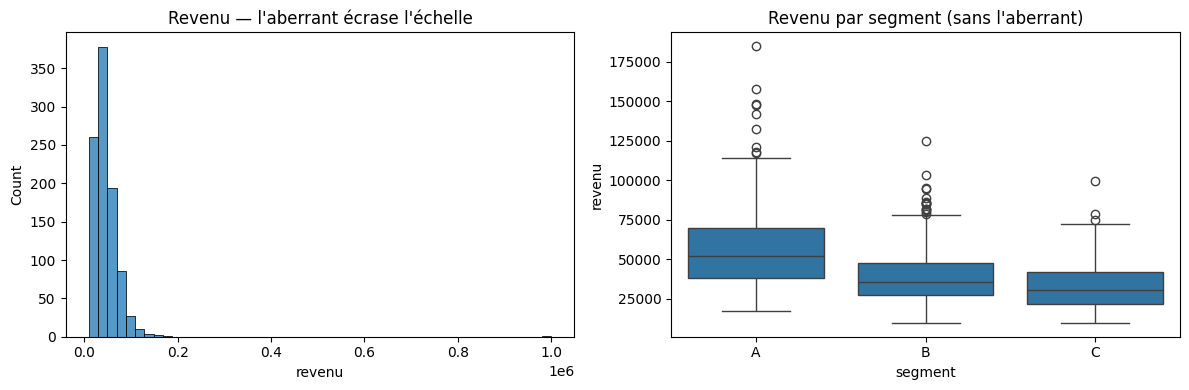

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["revenu"], bins=50, ax=axes[0])
axes[0].set_title("Revenu — l'aberrant écrase l'échelle")
sns.boxplot(data=sans_aberrant, x="segment", y="revenu", order=["A", "B", "C"], ax=axes[1])
axes[1].set_title("Revenu par segment (sans l'aberrant)")
plt.tight_layout()
plt.show()

### 4.4 Encodage et mise à l'échelle
Rappel du cours : une variable **quantitative** se met à l'échelle ; une variable **qualitative** s'**encode**.
1. Encodez `segment` en **one-hot** avec `pd.get_dummies`.
2. Normalisez `age` en **Min-Max** : $\dfrac{x - \min}{\max - \min}$ et standardisez-le en **Z-score** : $\dfrac{x - \bar{x}}{\sigma}$.

In [22]:
segment_onehot = pd.get_dummies(df["segment"], prefix="segment", dtype=int)
age_minmax     = (df["age"] - df["age"].min()) / (df["age"].max() - df["age"].min())
age_zscore     = (df["age"] - df["age"].mean()) / df["age"].std()

pd.concat([df[["segment", "age"]], segment_onehot,
           age_minmax.rename("age_minmax"), age_zscore.rename("age_zscore")], axis=1).head()

,segment,age,segment_A,segment_B,segment_C,age_minmax,age_zscore
0,C,18,0,0,1,0.000000,-2.033368
1,A,87,1,0,0,1.000000,3.844896
2,A,55,1,0,0,0.536232,1.118744
3,C,67,0,0,1,0.710145,2.141051
4,A,40,1,0,0,0.318841,-0.159139


💡 *Question à poser* : pourquoi ne pas encoder `segment` par A=1, B=2, C=3 ? → cela impose un **ordre et une distance** (C = 3 × A) qu'un modèle prendrait au sérieux. Le one-hot ne fait aucune hypothèse d'ordre ; l'encodage par entiers est réservé aux variables **ordinales**.

---
## Bilan
| Étape | Commande | Ce qu'on a appris |
|---|---|---|
| Import | `read_csv(sep=";")` | le séparateur conditionne tout |
| Dimensions / types | `shape`, `dtypes` | 1000 × 8, 6 numériques, 2 catégorielles |
| Manquants | `info()`, `isna().sum()` | 37 revenus manquants |
| Statistiques | `describe()`, `value_counts()` | segment A majoritaire (412) |
| Anomalie | `max()`, `quantile(0.99)` | 999 999 DA → à investiguer avant toute analyse |

> **À retenir :** on n'analyse jamais un jeu de données avant de l'avoir **exploré** : dimensions, types, valeurs manquantes, valeurs aberrantes.